## 06b (with background): SAI change + ensemble-mean background climate change

Same final figure as `06b_Result_maps_dT_dP_compared_to_CMIP7`, but every panel (including the CMIP7
stabilization column) shows ensemble-mean no-SAI background change (SAI year vs. baseline period) + CIDER SAI change.

Set `add_background=False` in the final call to reproduce the SAI-only maps. 

In [1]:
import xarray as xr, numpy as np, pandas as pd
import matplotlib.pyplot as plt, cartopy.crs as ccrs
import matplotlib.cm as cm, matplotlib.colors as mcolors
from matplotlib.patches import Patch
import cartopy.feature as cfeature

from functions import build_country_weights, verify_population_coverage, EU_MEMBERS,\
                        country_weights_dict, baseline_start, baseline_end, lat_to_str_dict, \
                        cider_inj_lats_popweighted, basepath, cpath, cider_combined, pop, \
                        countries_zip_path, select_eu_mode, reorient_netcdf, areaweighted_mean

<xarray.Dataset> Size: 9MB
Dimensions:  (time: 60, lon: 192, lat: 96)
Coordinates:
  * time     (time) object 480B 2029-11-15 00:00:00 ... 2034-10-16 00:00:00
  * lon      (lon) float64 2kB 0.0 1.875 3.75 5.625 ... 352.5 354.4 356.2 358.1
  * lat      (lat) float64 768B -88.57 -86.72 -84.86 -83.0 ... 84.86 86.72 88.57
Data variables:
    T        (time, lat, lon) float64 9MB -0.003184 -0.003183 ... -1.327 -1.326
Attributes:
    CDI:          Climate Data Interface version 2.0.4 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    description:  Dataset converted from NumPy array with dimensions (lon, la...
    history:      Mon Oct 19 14:16:48 2026: cdo -remapbil,/home/msaenger/REST...
    CDO:          Climate Data Operators version 2.0.4 (https://mpimet.mpg.de...

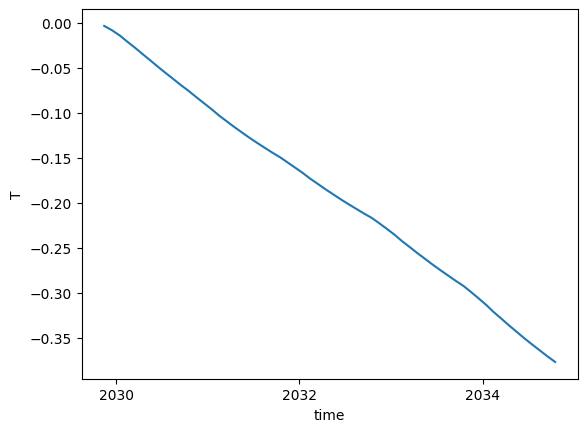

In [2]:
## CMIP7 stabilization scenario in which optimal injection rates for 1.5C stabilization are deployed
## at 30S and 30N simultaneously

cider_cmip7_stabilize = xr.open_dataset(
    '/home/msaenger/CIDER/CMIP7_stabilization/TREFHT/002_1.0_Tgyr.nc_regridded.nc')

areaweighted_mean(cider_cmip7_stabilize.T).plot()

cider_cmip7_stabilize

In [3]:
n_members = 500
newpath = basepath + f'{n_members}_members/' 

ssp_plus_invert = xr.open_dataset(newpath + 
                    f'SSP370_plus_InVERT_{n_members}member_ensemble_TREFHT_2015_to_2065.nc')

baseline_start = '2025'
baseline_end = '2034'

baseline = ssp_plus_invert.sel(time=slice(baseline_start, baseline_end))

baseline

<xarray.Dataset> Size: 9GB
Dimensions:   (time: 120, lat: 96, ensemble: 500, lon: 192)
Coordinates:
  * time      (time) object 960B 2025-01-16 00:00:00 ... 2034-12-16 00:00:00
  * lat       (lat) float64 768B -88.57 -86.72 -84.86 ... 84.86 86.72 88.57
    month     (time) int64 960B ...
  * ensemble  (ensemble) int64 4kB 0 1 2 3 4 5 6 ... 493 494 495 496 497 498 499
  * lon       (lon) float64 2kB -178.1 -176.2 -174.4 ... 176.2 178.1 180.0
Data variables:
    TREFHT    (time, lat, lon, ensemble) float64 9GB ...
    gmean     (time, ensemble) float64 480kB ...

In [4]:
## Load 'Default' test results for min injection rate to convince population of success

### Values of sensitivity-tested parameters
buffer_months = 12
tau = 12
eval_months = 36

### Where results are saved for this set of parameters
rpath = newpath + \
        f'results_buffer={buffer_months}m_tau={tau}m_eval={eval_months}m/'
print(rpath)

k_setting = 'country_k'
eu_mode = 'aggregated'

/home/msaenger/Perceptions_2025/cleaned_code/500_members/results_buffer=12m_tau=12m_eval=36m/


In [5]:
## Folded country polygons (labels match country_da/W_norm_eu exactly) 
countries = country_weights_dict['countries_gdf']

verify_population_coverage(country_weights_dict)

PASSED -- Population coverage: 100.000000% (8.016736e+09 of 8.016736e+09 people-equivalent) accounted for across kept country rows.


{'population_total': 8016736089.992069,
 'population_accounted': 8016736089.992069,
 'coverage_frac': 1.0,
 'passed': True}

In [6]:
## Load min injection rate datasets with NaNs replaced with max possible rate

inj_rates_single_lat = xr.open_dataset(rpath + \
                            f'single_lat_min_rates_{k_setting}_EU_agg_nans_replaced.nc')
inj_rates_uniform = xr.open_dataset(rpath + \
                            f'global_uniform_min_rates_{k_setting}_EU_agg_nans_replaced.nc')

### Plot maps of dT and dP for customizable percentile injection rates for each deploying country

In [7]:
def compute_var_diff(deploying_country, pctile, injection_type,
                     inj_rates_single_lat, inj_rates_uniform,
                     year, cider_da=cider_combined):
    '''
    Compute the gridded difference between year N of a CIDER SAI  injection run and the counterfactual
    (no SAI from CIDER)
    Inputs:
        deploying_country (str)
        pctile (int, 0-100): percentile of the country's minimum injection
            rate distribution to evaluate CIDER at
        injection_type (str): 'single_lat' or 'uniform'
        cider_da: raw CIDER DataArray (dims include injection_lat, injection_rate, time) 
            -- the CIDER *delta*, not yet combined with any background
        baseline_std: (lat, lon) field
    Returns:
        diff (lat, lon): SAI forced response
        pctile_rate (float): the injection rate (Tg/yr) this was evaluated at
    '''
    min_rates_ds = inj_rates_single_lat if injection_type == 'single_lat' else inj_rates_uniform
    min_rates = min_rates_ds.sel(country=deploying_country).min_injection_rate.values
    min_rates = min_rates[~np.isnan(min_rates)]

    ## Choose nearest higher percentile value from available data
    pctile_rate = np.percentile(min_rates, pctile, method='higher')

    if injection_type == 'single_lat':
        inj_lat = lat_to_str_dict[cider_inj_lats_popweighted.sel(
                        country=deploying_country).nearest_cider_lat.values.tolist()]
        var_cider = cider_da.sel(injection_lat=inj_lat, injection_rate=pctile_rate)
    else:
        var_cider = cider_da.sel(injection_lat='uniform', injection_rate=pctile_rate)

    if year == 1:
        diff = var_cider.isel(time=slice(0, 12))
    if year == 2:
        diff = var_cider.isel(time=slice(12, 24))
    
    mean_diff = diff.mean('time')

    return mean_diff, pctile_rate, year

In [8]:
def compute_stabilize_diff(stabilize_da, year):
    '''
    Mean over year 1 or 2 of the CMIP7 stabilization run (optimized inj in Tg/yr at 30S + 30N).
    Same time slicing as compute_var_diff().
    Returns: mean_diff (lat, lon)
    '''
    if year == 1:
        diff = stabilize_da.isel(time=slice(0, 12))
    if year == 2:
        diff = stabilize_da.isel(time=slice(12, 24))

    return diff.mean('time')

In [9]:
def compute_T_diff(deploying_country, pctile, injection_type, 
                    inj_rates_single_lat, inj_rates_uniform, 
                    year, cider_da=cider_combined):
    '''
    Computes gridded standardized TREFHT mean delta in year 1 or 2 of a CIDER SAI injection 
    run Thin T-specific wrapper around compute_var_diff()

    Returns:
        T_diff (lat, lon, in K), pctile_rate (float, Tg/yr)
    '''
    return compute_var_diff(deploying_country, pctile, injection_type, 
                              inj_rates_single_lat, inj_rates_uniform, 
                              year, cider_da)

In [10]:
## Load baseline precip data
ppath = '/home/msaenger/Perceptions_2025/cleaned_code/LENS2_SSP370/precip/'
baseline_precip = xr.open_dataset(ppath + 'PRECT_combined_2015-2024.nc')

## Load combined CIDER precip dataset
cider_output_path = basepath + 'CIDER_output/PRECIP/'
cider_precip_combined = xr.open_dataset(cider_output_path + \
                'CIDER_PRECT_output_combined_1.0_Tg_increments_first_5_years.nc').P
cider_precip_combined

<xarray.DataArray 'P' (injection_lat: 8, injection_rate: 250, time: 60,
                       lat: 96, lon: 192)> Size: 18GB
[2211840000 values with dtype=float64]
Coordinates:
  * lat             (lat) float64 768B -88.57 -86.72 -84.86 ... 86.72 88.57
  * lon             (lon) float64 2kB -178.1 -176.2 -174.4 ... 176.2 178.1 180.0
  * injection_rate  (injection_rate) float64 2kB 1.0 2.0 3.0 ... 249.0 250.0
  * injection_lat   (injection_lat) <U7 224B '60S' '30S' ... '60N' 'uniform'
  * time            (time) int64 480B 0 1 2 3 4 5 6 7 ... 53 54 55 56 57 58 59
Attributes:
    CDI_grid_type:     gaussian
    CDI_grid_num_LPE:  48

In [11]:
## CMIP7 stabilization scenario for precip: same optimized injection rates as above for TREFHT
cider_precip_cmip7_stabilize = xr.open_dataset('/home/msaenger/CIDER/CMIP7_stabilization/' + \
                                               'PRECT/002_1.0_PRECT_Tgyr.nc_PRECT_regridded.nc')

cider_precip_cmip7_stabilize

<xarray.Dataset> Size: 9MB
Dimensions:  (time: 60, lon: 192, lat: 96)
Coordinates:
  * time     (time) object 480B 2029-11-15 00:00:00 ... 2034-10-16 00:00:00
  * lon      (lon) float64 2kB 0.0 1.875 3.75 5.625 ... 352.5 354.4 356.2 358.1
  * lat      (lat) float64 768B -88.57 -86.72 -84.86 -83.0 ... 84.86 86.72 88.57
Data variables:
    P        (time, lat, lon) float64 9MB ...
Attributes:
    CDI:          Climate Data Interface version 2.0.4 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    description:  Dataset converted from NumPy array with dimensions (lon, la...
    history:      Mon Oct 19 14:18:37 2026: cdo -remapbil,/home/msaenger/REST...
    CDO:          Climate Data Operators version 2.0.4 (https://mpimet.mpg.de...

In [12]:
## Convert longitude to -180 to 180 from 0-360
baseline_precip = reorient_netcdf(baseline_precip)

## Convert baseline_precip from m/s (CESM/LENS2 native units) to mm/day to match CIDER units
## 1 m/s * 1000 mm/m * 86400 s/day = 86,400,000 mm/day per (m/s)
M_PER_S_TO_MM_PER_DAY = 1000 * 86400
baseline_precip['PRECT'] = baseline_precip['PRECT'] * M_PER_S_TO_MM_PER_DAY
baseline_precip['PRECT'].attrs['units'] = 'mm/day'

baseline_precip

<xarray.Dataset> Size: 885MB
Dimensions:   (ensemble: 50, time: 120, lat: 96, lon: 192)
Coordinates:
  * time      (time) object 960B 2015-01-16 00:00:00 ... 2024-12-16 00:00:00
  * lat       (lat) float64 768B -88.57 -86.72 -84.86 ... 84.86 86.72 88.57
  * ensemble  (ensemble) int64 400B 0 1 2 3 4 5 6 7 ... 42 43 44 45 46 47 48 49
  * lon       (lon) float64 2kB -178.1 -176.2 -174.4 ... 176.2 178.1 180.0
Data variables:
    PRECT     (ensemble, time, lat, lon) float64 885MB 0.02946 ... 0.7837
Attributes:
    CDI:          Climate Data Interface version 2.0.4 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    history:      Mon Jul 27 15:54:01 2026: cdo -remapbil,/home/msaenger/REST...
    CDO:          Climate Data Operators version 2.0.4 (https://mpimet.mpg.de...

In [13]:
ppath

'/home/msaenger/Perceptions_2025/cleaned_code/LENS2_SSP370/precip/'

In [14]:
## ---- Background (no-SAI) climate: config + data ----
SAI_START_YEAR = 2035

## Full-period no-SAI precip (ensemble, monthly) that covers SAI_START_YEAR and SAI_START_YEAR+1
bg_precip = xr.open_mfdataset(ppath + 'PRECT_combined*.nc', concat_dim='time', 
                              combine='nested', parallel=True)
bg_precip

<xarray.Dataset> Size: 1GB
Dimensions:   (ensemble: 50, time: 360, lat: 96, lon: 192)
Coordinates:
  * time      (time) object 3kB 2015-01-16 00:00:00 ... 2044-12-16 00:00:00
  * lon       (lon) float64 2kB 0.0 1.875 3.75 5.625 ... 352.5 354.4 356.2 358.1
  * lat       (lat) float64 768B -88.57 -86.72 -84.86 ... 84.86 86.72 88.57
  * ensemble  (ensemble) int64 400B 0 1 2 3 4 5 6 7 ... 42 43 44 45 46 47 48 49
Data variables:
    PRECT     (ensemble, time, lat, lon) float32 1GB dask.array<chunksize=(50, 1, 96, 192), meta=np.ndarray>
Attributes:
    CDI:          Climate Data Interface version 2.0.4 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    history:      Mon Jul 27 15:54:01 2026: cdo -remapbil,/home/msaenger/REST...
    CDO:          Climate Data Operators version 2.0.4 (https://mpimet.mpg.de...

In [15]:
bg_precip = reorient_netcdf(bg_precip)
bg_precip['PRECT'] = bg_precip['PRECT'] * M_PER_S_TO_MM_PER_DAY      # m/s -> mm/day
bg_precip['PRECT'].attrs['units'] = 'mm/day'

for _name, _da in [('TREFHT', ssp_plus_invert.TREFHT), ('PRECT', bg_precip.PRECT)]:
    _have = set(_da.time.dt.year.values.tolist())
    _need = {SAI_START_YEAR, SAI_START_YEAR + 1}
    if not _need <= _have:
        raise ValueError(f'{_name} background covers {min(_have)}-{max(_have)} but needs {sorted(_need)}. '
                         'Point precip_bg_file / ssp_plus_invert at files that include the SAI years.')
        
bg_precip

<xarray.Dataset> Size: 3GB
Dimensions:   (ensemble: 50, time: 360, lat: 96, lon: 192)
Coordinates:
  * time      (time) object 3kB 2015-01-16 00:00:00 ... 2044-12-16 00:00:00
  * lat       (lat) float64 768B -88.57 -86.72 -84.86 ... 84.86 86.72 88.57
  * ensemble  (ensemble) int64 400B 0 1 2 3 4 5 6 7 ... 42 43 44 45 46 47 48 49
  * lon       (lon) float64 2kB -178.1 -176.2 -174.4 ... 176.2 178.1 180.0
Data variables:
    PRECT     (ensemble, time, lat, lon) float64 3GB dask.array<chunksize=(50, 1, 96, 192), meta=np.ndarray>
Attributes:
    CDI:          Climate Data Interface version 2.0.4 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    history:      Mon Jul 27 15:54:01 2026: cdo -remapbil,/home/msaenger/REST...
    CDO:          Climate Data Operators version 2.0.4 (https://mpimet.mpg.de...

In [16]:
def compute_P_diff(deploying_country, pctile, injection_type,
                     inj_rates_single_lat, inj_rates_uniform,
                     year, cider_da=cider_precip_combined):
    '''
    Compute gridded standardized precipitation delta averaged across year 1 or 2 of a 
    CIDER SAI injection run in units of the LENS2 SSP370 baseline's internal-variability 
    standard deviation. Thin P-specific wrapper around compute_var_diff() 
    Returns:
        P_zscore (lat, lon), P_diff (lat, lon, in mm/day), pctile_rate (float, Tg/yr)
    '''
    return compute_var_diff(deploying_country, pctile, injection_type,
                               inj_rates_single_lat, inj_rates_uniform,
                               year, cider_da)

In [17]:
def match_grid(da, target):
    '''Return da on target's (lat, lon) grid, with longitudes in -180..180 (180 kept as 180,
    as in the CIDER grid). Exact-grid matches just get target's coords; otherwise interpolate.'''
    if float(da.lon.max()) > 180:
        da = da.assign_coords(lon=da.lon.where(da.lon <= 180, da.lon - 360)).sortby('lon')
    same = (da.lat.size == target.lat.size and da.lon.size == target.lon.size
            and np.allclose(da.lat, target.lat) and np.allclose(da.lon, target.lon))
    if same:
        return da.assign_coords(lat=target.lat, lon=target.lon)
    return da.interp(lat=target.lat, lon=target.lon)


def compute_background_diff(bg_da, year, sai_start_year=SAI_START_YEAR):
    '''
    Ensemble-mean change in the no-SAI background climate for SAI year 1 or 2:
        mean(ensemble, calendar year sai_start_year + year - 1) - mean(ensemble, baseline period)
    bg_da: DataArray with dims (time, lat, lon, <any ensemble dim(s)>)
    Returns (lat, lon) DataArray in the units of bg_da.
    '''
    cal_year = sai_start_year + year - 1
    avg_dims = [d for d in bg_da.dims if d not in ('lat', 'lon')]     # time + ensemble dim(s)

    cur = bg_da.sel(time=slice(f'{cal_year}-01-01', f'{cal_year}-12-31'))
    if cur.sizes['time'] != 12:
        raise ValueError(f'Expected 12 months for {cal_year}, found {cur.sizes["time"]}')
    ref = bg_da.sel(time=slice(baseline_start, baseline_end))

    return (cur.mean(avg_dims) - ref.mean(avg_dims)).compute()


### Combined T & P difference maps: temperature (top row) and precipitation (bottom row), aligned by injection strategy (columns)

In [18]:
def plot_gridded_TP_diff_comparison(deploying_country, inj_rates_single_lat, inj_rates_uniform, 
                                    pctile, year, 
                                    injection_types=('single_lat', 'uniform'),
                                    vmax_T=None, vmax_P=None,
                                    stabilize_T=cider_cmip7_stabilize.T,
                                    stabilize_P=cider_precip_cmip7_stabilize.P,
                                    add_background=True,
                                    bg_T=ssp_plus_invert.TREFHT,
                                    bg_P=bg_precip.PRECT):
    '''
    Plot temp and precip CIDER difference maps for one deploying country

    Inputs mirror the individual T/P comparison functions:
        deploying_country (str)
        inj_rates_single_lat, inj_rates_uniform: injection-rate datasets
        pctile (int, 0-100): percentile of the country's minimum injection
            rate distribution to evaluate CIDER at
        injection_types (tuple of str): 'uniform' and/or 'single_lat',
            one column per entry, in the given order
        vmax_T, vmax_P (float, optional): shared symmetric color limits for
            the temp and precip rows respectively. Defaults to the 95th percentile of 
            |diff| across all columns
        stabilize_T, stabilize_P: CMIP7 stabilization (1 Tg/yr at 30S + 30N) T and P
            DataArrays, plotted as an extra rightmost column
        add_background (bool): if True, plot (ensemble-mean no-SAI background climate change)
            + (CIDER SAI change) in every panel; if False, reproduce the SAI-only maps
        bg_T, bg_P: no-SAI background DataArrays with dims (time, lat, lon, <ensemble>).
            Background change = ensemble mean over the SAI year (SAI_START_YEAR + year - 1)
            minus ensemble mean over baseline_start:baseline_end
    '''
    ## Compute T and P difference maps for each injection strategy
    T_diffs, T_rates = {}, {}
    P_diffs, P_rates = {}, {}
    
    for injection_type in injection_types:
        
        T_diff, T_pctile_rate, year = compute_T_diff(deploying_country, pctile, injection_type,
                                                     inj_rates_single_lat, inj_rates_uniform, year)
        T_diffs[injection_type] = T_diff
        T_rates[injection_type] = T_pctile_rate

        P_diff, P_pctile_rate, year = compute_P_diff(deploying_country, pctile, injection_type,
                                                     inj_rates_single_lat, inj_rates_uniform, year)
        P_diffs[injection_type] = P_diff
        P_rates[injection_type] = P_pctile_rate

    ## CMIP7 stabilization scenario as an additional column
    T_diffs['stabilize'] = compute_stabilize_diff(stabilize_T, year)
    P_diffs['stabilize'] = compute_stabilize_diff(stabilize_P, year)
    T_rates['stabilize'] = P_rates['stabilize'] = 0.87
    col_keys = list(injection_types) + ['stabilize']

    ## Put the stabilization fields (lon 0-360) on the same grid as the CIDER country runs
    T_diffs['stabilize'] = match_grid(T_diffs['stabilize'], T_diffs[injection_types[0]])
    P_diffs['stabilize'] = match_grid(P_diffs['stabilize'], P_diffs[injection_types[0]])

    ## Add ensemble-mean background climate change (same field is added to every column)
    if add_background:
        bgT = match_grid(compute_background_diff(bg_T, year), T_diffs[injection_types[0]])
        bgP = match_grid(compute_background_diff(bg_P, year), P_diffs[injection_types[0]])
        for k in col_keys:
            T_diffs[k] = T_diffs[k] + bgT
            P_diffs[k] = P_diffs[k] + bgP
    suffix = '_with_background' if add_background else ''

    ## Shared, symmetric color limits per row
    if vmax_T is None:
        vmax_T = max(np.nanpercentile(np.abs(T_diffs[it]), 95) for it in col_keys)
    if vmax_P is None:
        vmax_P = max(np.nanpercentile(np.abs(P_diffs[it]), 95) for it in col_keys)
    
    vmin_T = -vmax_T
    vmin_P = -vmax_P

    n_cols = len(col_keys)
    fig, axes = plt.subplots(2, n_cols, figsize=(7.5 * n_cols, 8),
                             subplot_kw={'projection': ccrs.Robinson()})
    axes = np.atleast_2d(axes)
    
    if axes.shape[0] == 1:
        # subplots() returns a 1D array when n_cols == 1; force it into (2, 1)
        axes = axes.reshape(2, n_cols)

    def _injection_title(injection_type):
        pctile_rate = T_rates[injection_type]
        if injection_type == 'stabilize':
            return ('CMIP7 stabilization\n 1.7 Tg/yr total')

        if injection_type == 'single_lat':
            inj_lat = lat_to_str_dict[cider_inj_lats_popweighted.sel(
                            country=deploying_country).nearest_cider_lat.values.tolist()]
            return (f'Single latitude injection\n'
                    f'{pctile_rate:.0f} Tg/yr at {inj_lat}')
        else:
            return (f'Globally uniform injection\n'
                    f'{pctile_rate:.0f} Tg/yr total')

    panel_labels = [['(a)', '(d)'], ['(b)', '(e)'], ['(c)', '(f)']]
    
    T_mappable = P_mappable = None
        
    for (col, injection_type), (idx, label) in zip(enumerate(col_keys), enumerate(panel_labels)):

        ## Top row: temperature
        ax_T = axes[0, col]
        T_mappable = T_diffs[injection_type].plot(
            ax=ax_T, cmap='RdBu_r',
            vmin=vmin_T, vmax=vmax_T,
            transform=ccrs.PlateCarree(),
            zorder=0, add_colorbar=False)
        
        ax_T.add_feature(cfeature.BORDERS, linewidth=0.3, zorder=2)
        ax_T.add_feature(cfeature.OCEAN, color='gainsboro', zorder=1)
        ax_T.add_feature(cfeature.COASTLINE, linewidth=0.5, zorder=2)
        ax_T.set_title(_injection_title(injection_type), fontsize=18)
        
        ax_T.text(0.02, 1.06, label[0], transform=ax_T.transAxes, fontsize=14,
                fontweight='bold', va='top', ha='left', zorder=10)
            
        ## Bottom row: precipitation (same column/injection strategy)
        ax_P = axes[1, col]                    
        P_mappable = P_diffs[injection_type].plot(
            ax=ax_P, cmap='BrBG',
            vmin=vmin_P, vmax=vmax_P,
            transform=ccrs.PlateCarree(),
            zorder=0, add_colorbar=False)
        
        ax_P.add_feature(cfeature.BORDERS, linewidth=0.3, zorder=2)
        ax_P.add_feature(cfeature.OCEAN, color='gainsboro', zorder=1)
        ax_P.add_feature(cfeature.COASTLINE, linewidth=0.5, zorder=2)
        ax_P.set_title('')
        
        ax_P.text(0.02, 1.06, label[1], transform=ax_P.transAxes,
                fontsize=14, fontweight='bold', va='top', ha='left',
                zorder=10)

    ## Two separate colorbars, one per row, on the right-hand side
    fig.subplots_adjust(right=0.9, hspace=0.05, wspace=0.05)

    cbar_ax_T = fig.add_axes([0.91, 0.51, 0.015, 0.35])   # [left, bottom, width, height]
    cbar_T = fig.colorbar(T_mappable, cax=cbar_ax_T)
    cbar_T.ax.tick_params(labelsize=12)
    cbar_T.set_label('$\\Delta$T [K]' if not add_background else
                     f'$\\Delta$T vs. {baseline_start}-{baseline_end} [K]', fontsize=14)

    cbar_ax_P = fig.add_axes([0.91, 0.11, 0.015, 0.35])
    cbar_P = fig.colorbar(P_mappable, cax=cbar_ax_P)
    cbar_P.ax.tick_params(labelsize=12)
    cbar_P.set_label('$\\Delta$P [mm/day]' if not add_background else
                     f'$\\Delta$P vs. {baseline_start}-{baseline_end} [mm/day]', fontsize=14)

#     plt.suptitle(f'Year {year} of SAI deployed by {deploying_country} \n' + \
#                  'Mean SAI-forced change relative to background',
#                  y=1.04, fontsize=22)

    plt.savefig(rpath + f'Plots/{deploying_country}_dT_dP_map_{pctile}th_pctile_' + 
                                   f'{k_setting}{suffix}.pdf', bbox_inches='tight')
    
    plt.savefig(rpath + f'Plots/{deploying_country}_dT_dP_map_{pctile}th_pctile_' + 
                                   f'{k_setting}{suffix}.png', bbox_inches='tight')

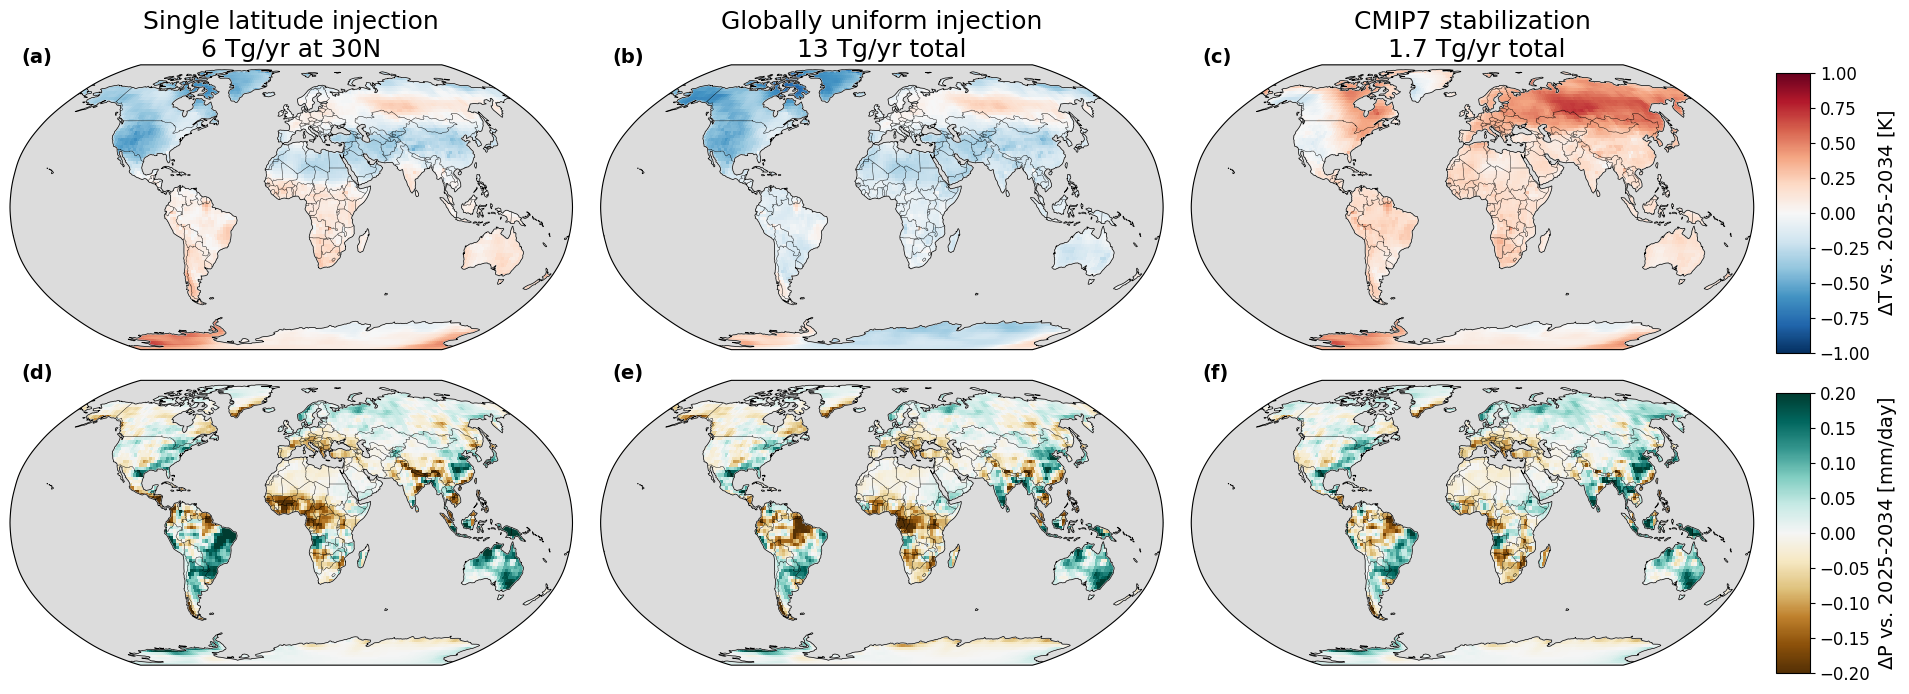

In [19]:
vmax_T = 1.0   
vmax_P = 0.2

deploying_country = 'United States of America'

plot_gridded_TP_diff_comparison(deploying_country, inj_rates_single_lat, inj_rates_uniform,
                                pctile=90, year=2, vmax_T=vmax_T, vmax_P=vmax_P,
                                add_background=True)


### 'optimal injection rates'
calculated in CIDER_30S_30N_1_5_optimal_injection_CLAUDE_with_piControl_baseline.ipynb

year_index,per_band_injection,total_injection
0,0.7551463040912798,1.5102926081825596
1,0.8678207363066286,1.7356414726132572
2,1.0536207348747086,2.1072414697494173
3,1.343751361321637,2.687502722643274
4,1.6520428885415797,3.3040857770831593

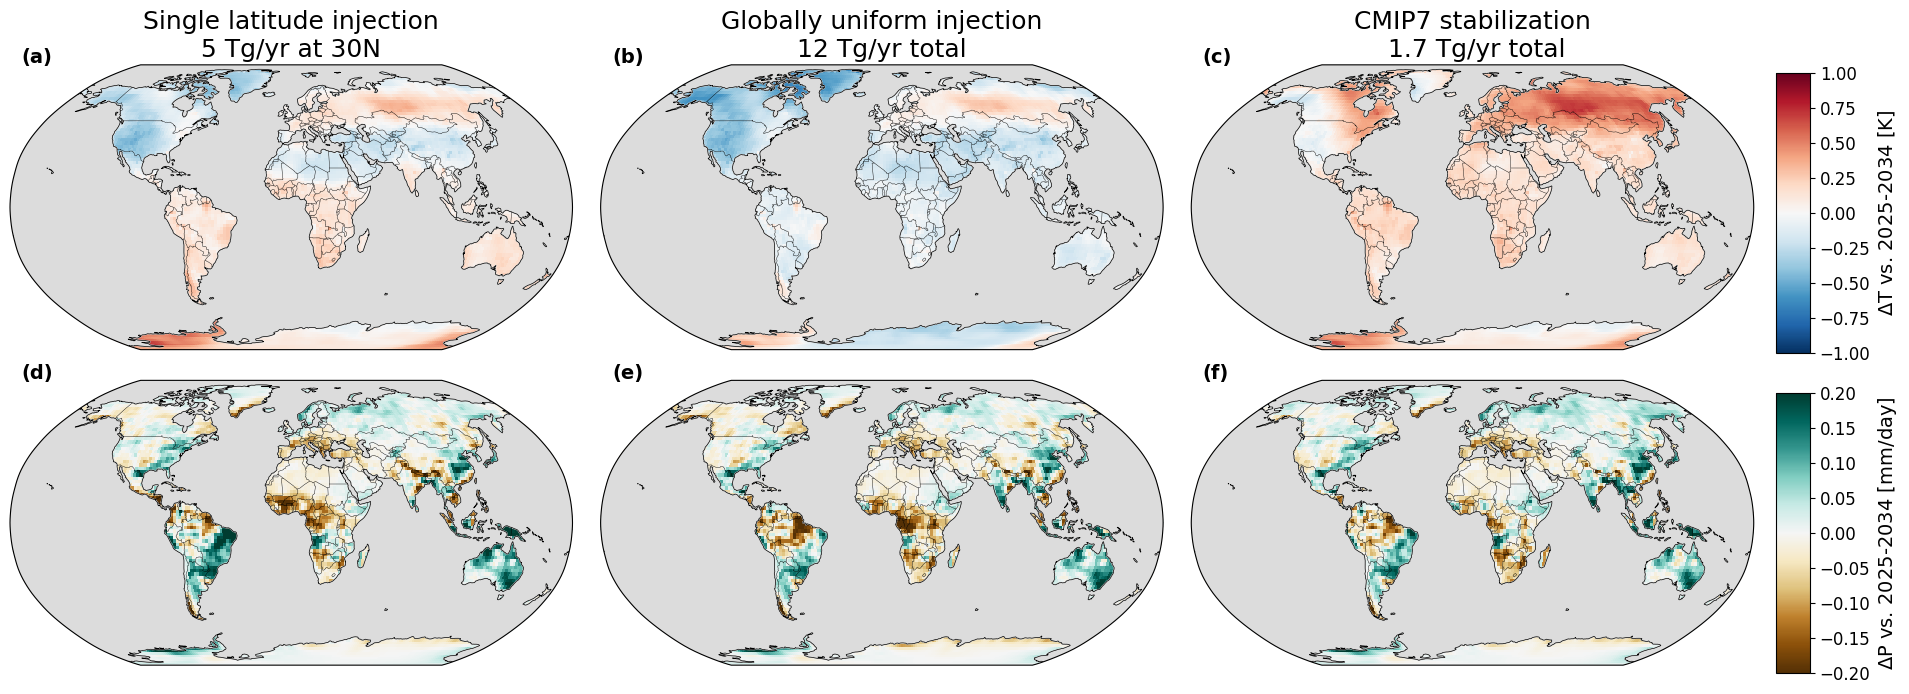

In [20]:
vmax_T = 1.0   
vmax_P = 0.2

deploying_country = 'China'

plot_gridded_TP_diff_comparison(deploying_country, inj_rates_single_lat, inj_rates_uniform,
                                pctile=90, year=2, vmax_T=vmax_T, vmax_P=vmax_P,
                                add_background=True)

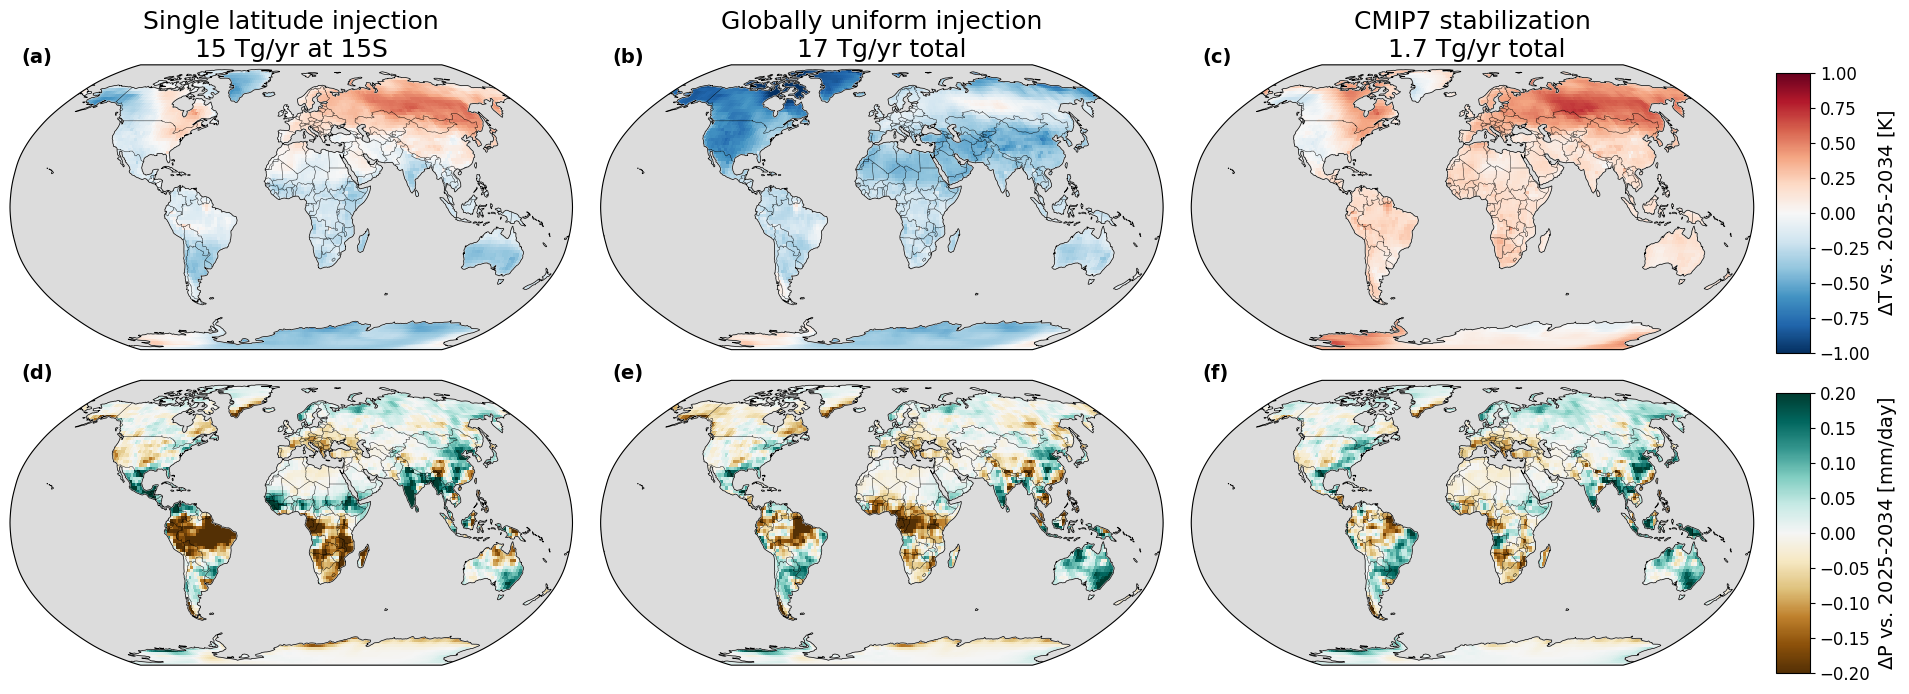

In [21]:
vmax_T = 1.0   
vmax_P = 0.2

deploying_country = 'Brazil'

plot_gridded_TP_diff_comparison(deploying_country, inj_rates_single_lat, inj_rates_uniform,
                                pctile=90, year=2, vmax_T=vmax_T, vmax_P=vmax_P,
                                add_background=True)

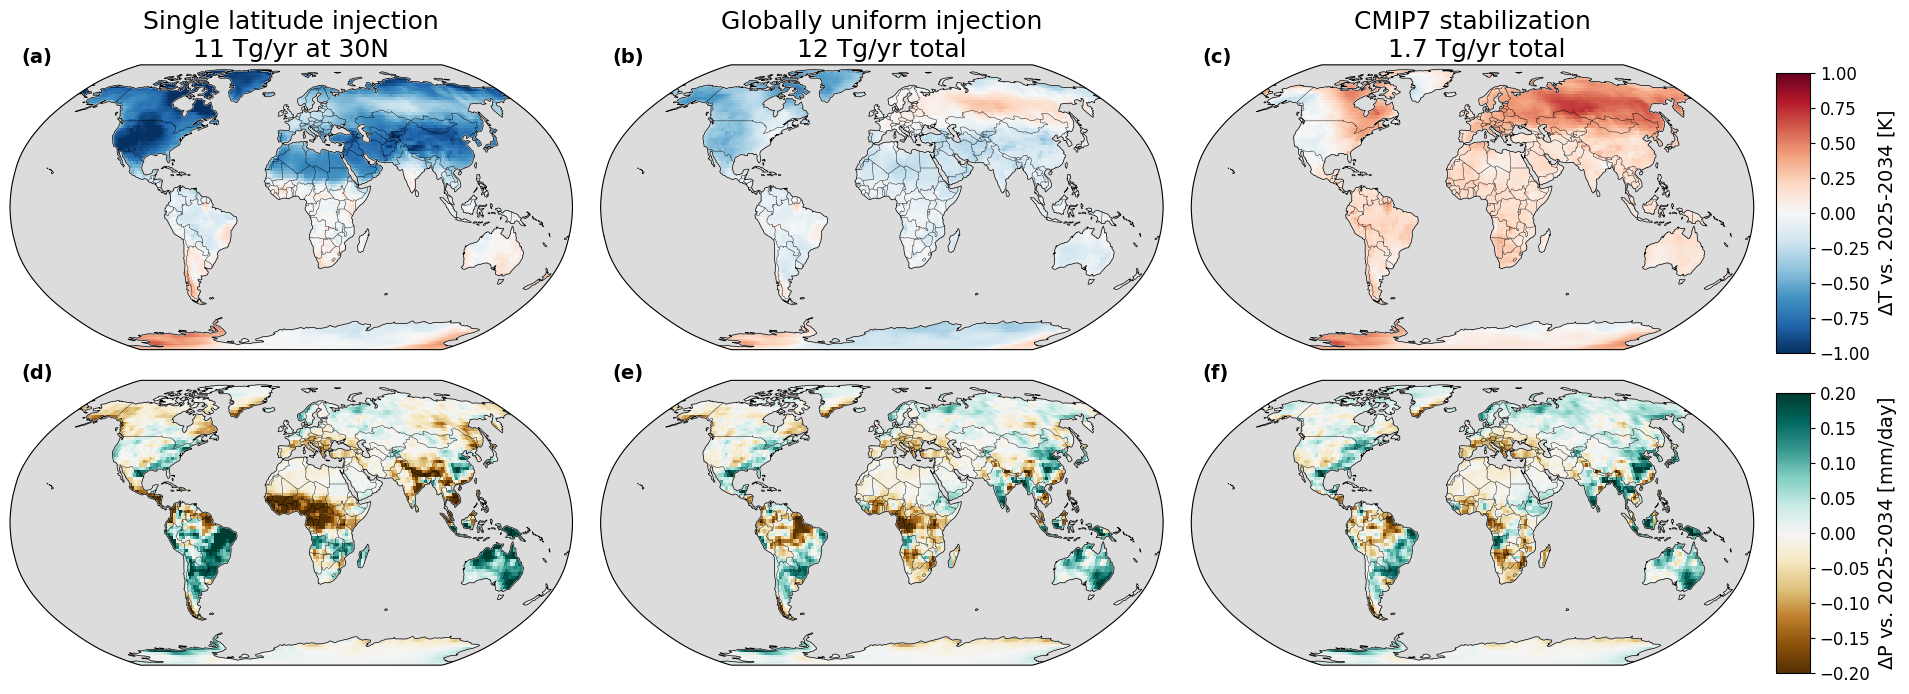

In [22]:
vmax_T = 1.0   
vmax_P = 0.2

deploying_country = 'India'

plot_gridded_TP_diff_comparison(deploying_country, inj_rates_single_lat, inj_rates_uniform,
                                pctile=90, year=2, vmax_T=vmax_T, vmax_P=vmax_P,
                                add_background=True)

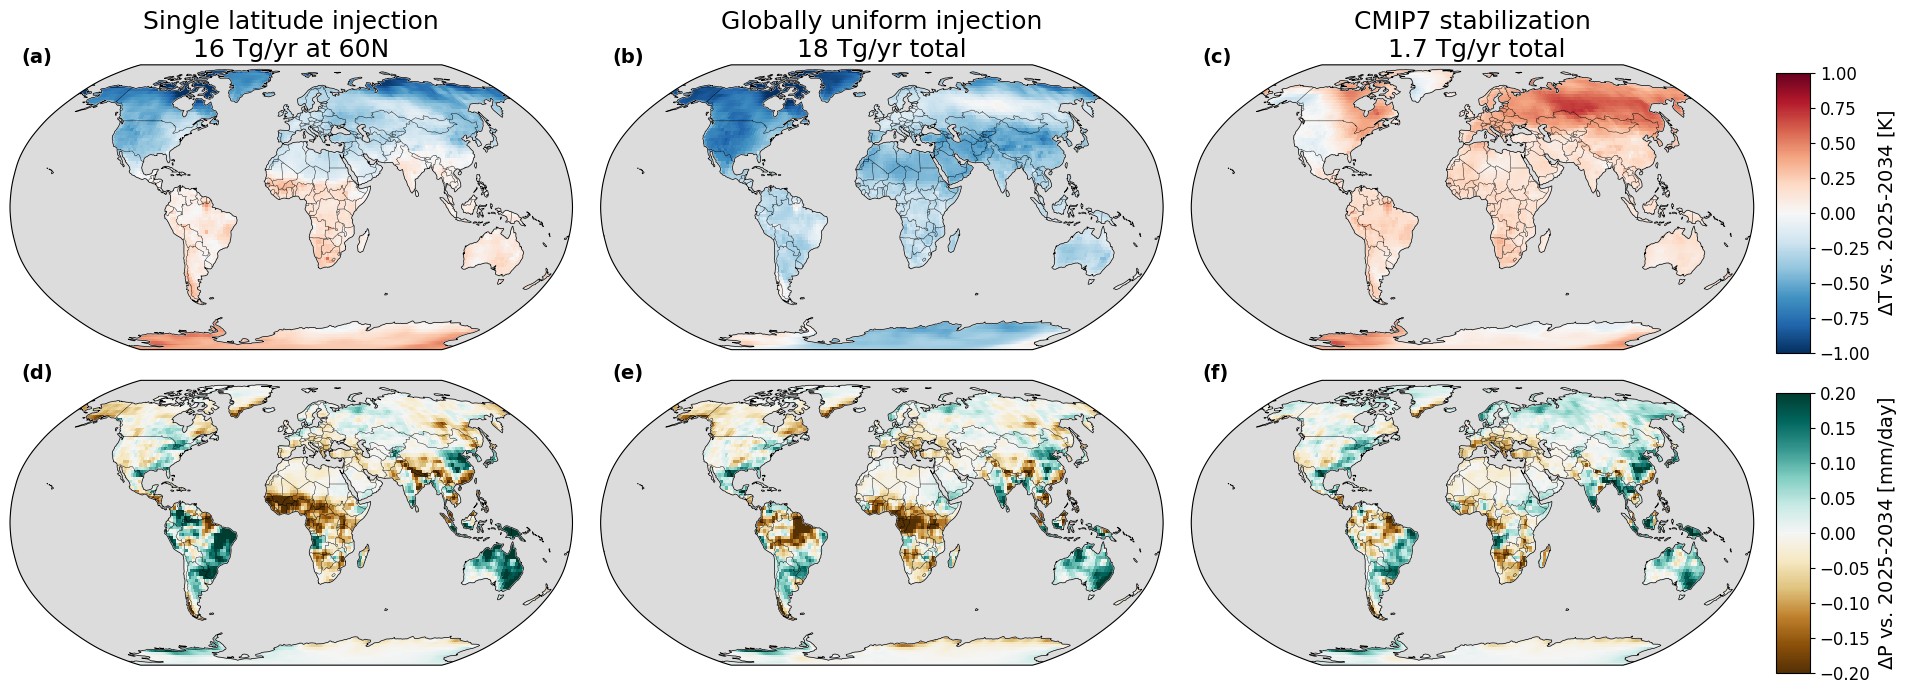

In [23]:
vmax_T = 1.0   
vmax_P = 0.2

deploying_country = 'European Union'

plot_gridded_TP_diff_comparison(deploying_country, inj_rates_single_lat, inj_rates_uniform,
                                pctile=90, year=2, vmax_T=vmax_T, vmax_P=vmax_P,
                                add_background=True)

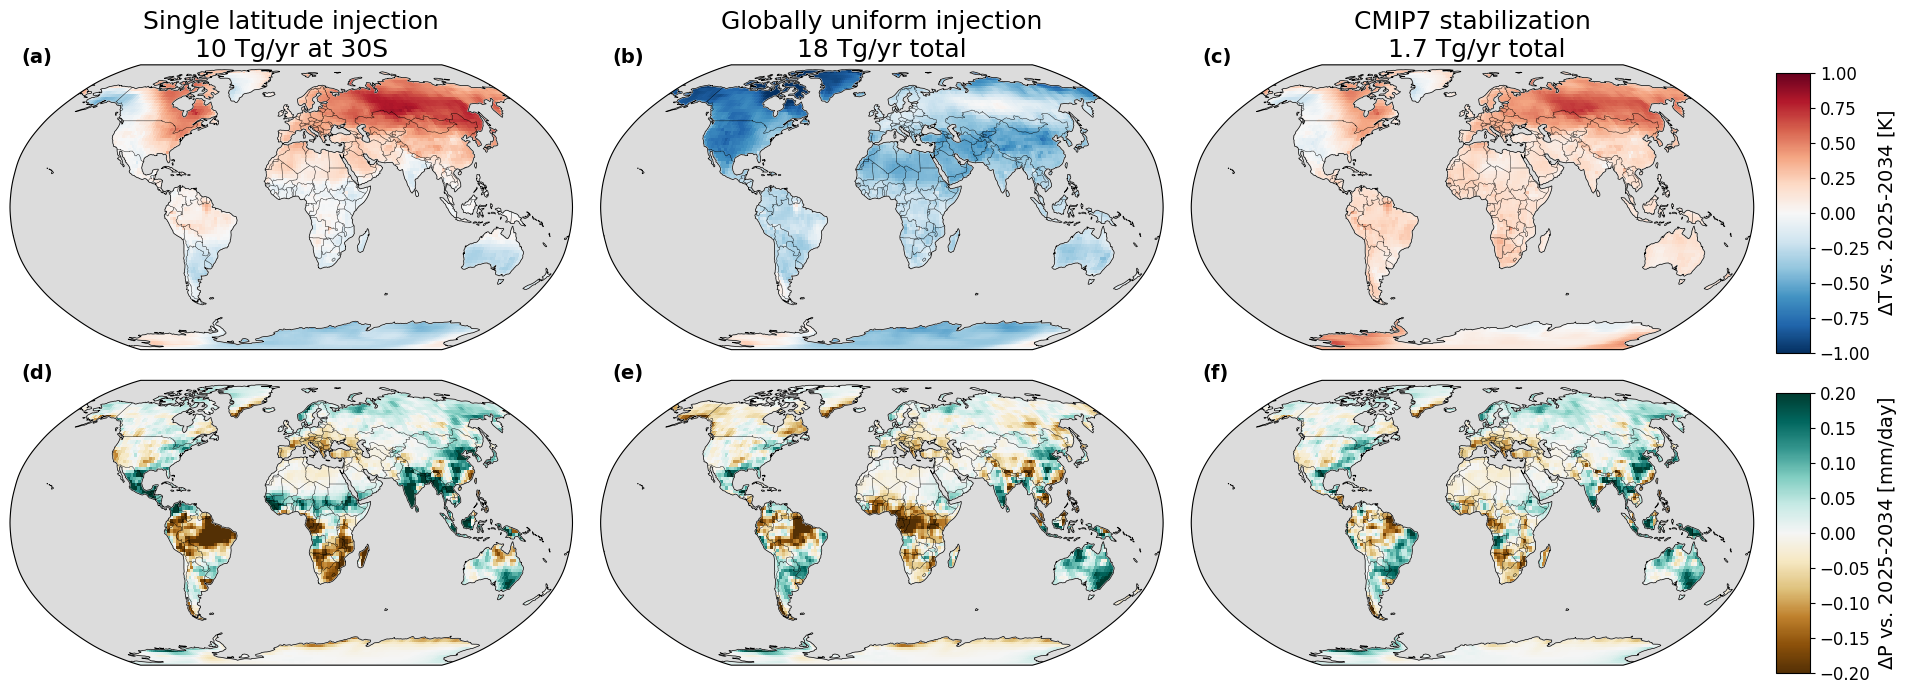

In [24]:
vmax_T = 1.0   
vmax_P = 0.2

deploying_country = 'Australia'

plot_gridded_TP_diff_comparison(deploying_country, inj_rates_single_lat, inj_rates_uniform,
                                pctile=90, year=2, vmax_T=vmax_T, vmax_P=vmax_P,
                                add_background=True)